In [2]:
#imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
#data checks
raw = pd.read_csv(r"D:\Python_Ironhack_precourse\exercises\Wk3\lab-eda-univariate\amz_uk_price_prediction_dataset.csv\amz_uk_price_prediction_dataset.csv")

#Plot prep
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4.5)
pd.set_option("display.max_columns", None)


 The File is loaded now. we can also prepare it for analysis. The question asked is to create a frequency table of the category. To do this, I will be copying the dataset, then modify ONLY for the category column.

In [3]:
#copy the data, good NDE practice.
category = raw.copy()

category['category'].value_counts().head(5)


Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: category, dtype: int64

We see that the top 5 products are: Sports, Beauty, Handmade Cloting, Bathroom products, and Birthday gifts.

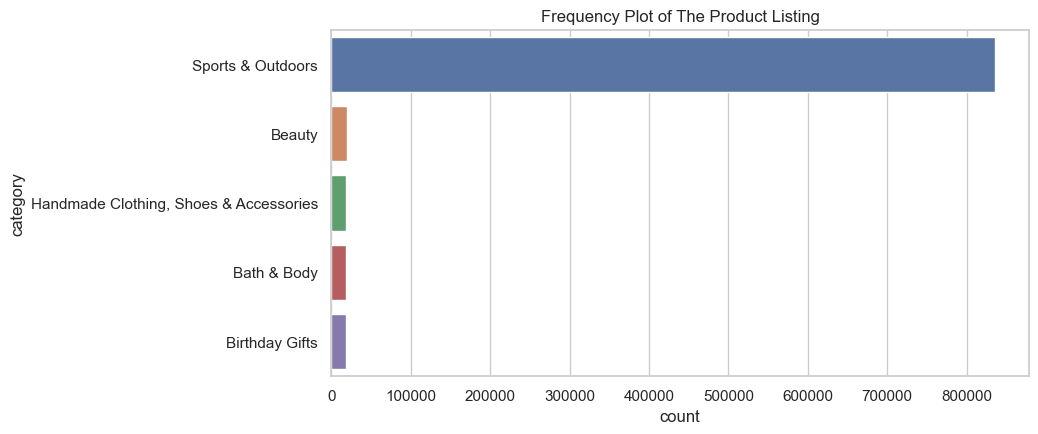

In [4]:
#Visuals
ordered = category['category'].value_counts().head(5).index
sns.countplot(data=category, y= 'category', order = ordered)
plt.title("Frequency Plot of The Product Listing")
plt.show()

I have issues rendering the whole frequency plot, so I went with the exercise suggestion of plotting only the top 5 categories. It is interesting that ALL of the other categories dwarfs in comparison to the Sports and Outdoors purchases!

For the second part, I will be using the describe and info function, to gleam into the data and infer from them. I am specifically interested in the price column.

In [5]:
raw['price'].describe().round(3)


count    2443651.000
mean          89.244
std          345.609
min            0.000
25%            9.990
50%           19.090
75%           45.990
max       100000.000
Name: price, dtype: float64

In [6]:
raw['price'].mode()


0    9.99
dtype: float64

In [7]:
raw['price'].median()

19.09

The mean price point would be at $89.24, and the common price point is at $9.99. This means that there are some outliers that pulls up the price to the mean value, and can be seen with the max price at $100k. The median is closer to the mode at $19.1, but it is still susceptible to the outlier price.

In [8]:
variance_price = int((raw['price'].std())**2)
print(variance_price)

119445


In [9]:
range = raw['price'].max()-raw['price'].min()
print(range)

100000.0


With the variance at 119K and the standard deviation at 346, it seems like the data is heavily skewed by some anomalous pricing that has a low order count. The range is the same as the max price, and that it is in the same order of magnitude with the variance!

In [10]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [38]:
#Visuals
prices = raw.copy()

prices['price']



0          21.99
1          23.99
2          21.99
3          31.99
4          17.99
           ...  
2443646    22.34
2443647    97.99
2443648    52.99
2443649    79.99
2443650    53.99
Name: price, Length: 2443651, dtype: float64

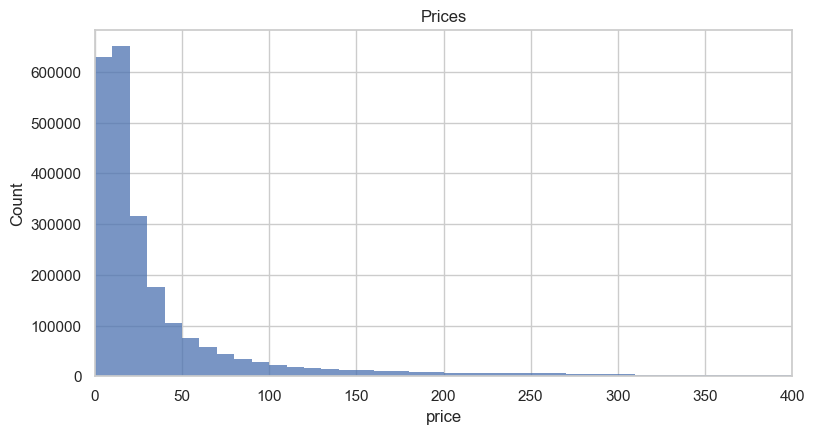

In [46]:

hist = sns.histplot(prices['price'], bins = 10000)
hist.set_xlim(left =0, right = 400)
plt.title('Prices')
plt.show()

Most of the prices are at the $10 to $20 range. It was initially difficult to get a read from the plot so I settled on 10000 bins and used a more limited x axis range (up to $400), because the date is left-skewed, so I can pinpoint the range at lower values.

In [48]:
# Part 3.

rating = raw.copy()

rating['reviews'].describe().round(3)

count    2443651.000
mean         480.628
std         5944.124
min            0.000
25%            0.000
50%            0.000
75%           59.000
max      1356658.000
Name: reviews, dtype: float64

In [54]:
def dispersion(reviews):
    return pd.Series({
        "variance": reviews.var(),
        "std": reviews.std(),
        "range": reviews.max() - reviews.min(),
        "IQR": reviews.quantile(0.75) - reviews.quantile(0.25),
    })

pd.DataFrame({
    "Reviews": dispersion(rating["reviews"]).round(2),
})

,Reviews
variance,35332611.92
std,5944.12
range,1356658.00
IQR,59.00


There is a wide variation of customer feedback, based on the large orders of magnitude in the variance AND the standard deviation. The range of feedback paints a picture that some products have only few reviews, whilst other products are heavily reviewed. This could mean there is a bias amongst customers.

In [57]:
rating['reviews']

0          15308
1          98099
2          15308
3           7205
4           1881
           ...  
2443646        0
2443647        0
2443648        0
2443649      404
2443650       34
Name: reviews, Length: 2443651, dtype: int64

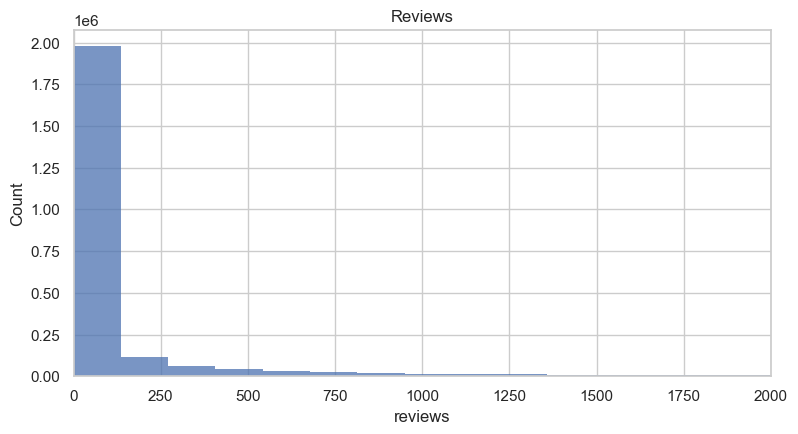

In [65]:
hist_reviews = sns.histplot(prices['reviews'], bins = 10000)
hist_reviews.set_xlim(left =0, right = 2000)
plt.title('Reviews')
plt.show()

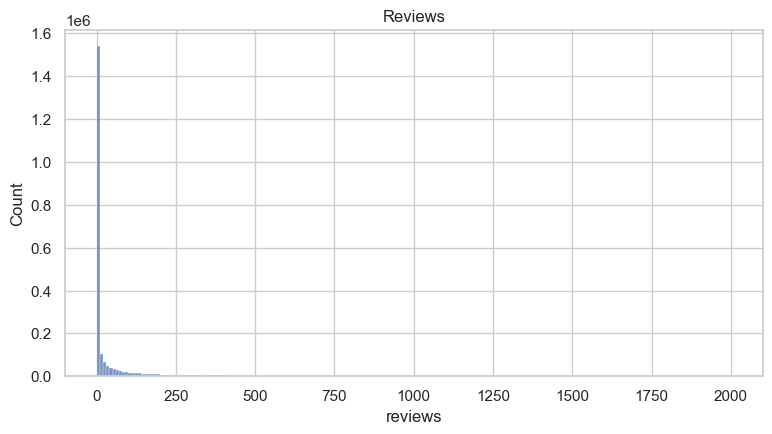

In [70]:
#Better granularity plot
reviews_plot = prices.loc[
    prices["reviews"].between(0, 2000),
    "reviews"
]

ax = sns.histplot(reviews_plot, binwidth=10)
ax.set_title("Reviews")
plt.show()

Based on this, we see that most reviews are at 0. This could be removed and studied separately, which I will be doing in the next steps.

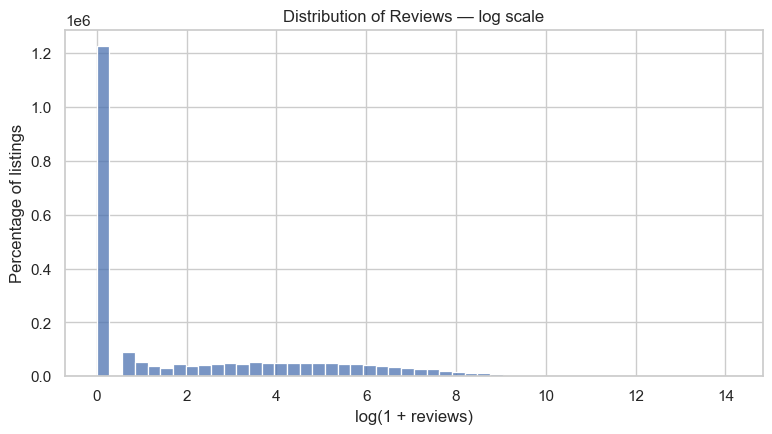

In [75]:
reviews_log = np.log1p(prices["reviews"])

ax = sns.histplot(
    reviews_log,
    bins=50,
    stat="count"
)

ax.set_title("Distribution of Reviews — log scale")
ax.set_xlabel("log(1 + reviews)")
ax.set_ylabel("Percentage of listings")
plt.show()

This plot is now in the log scale, to show how big of a range I am looking at. I also used the log1p method to single out the zero values.

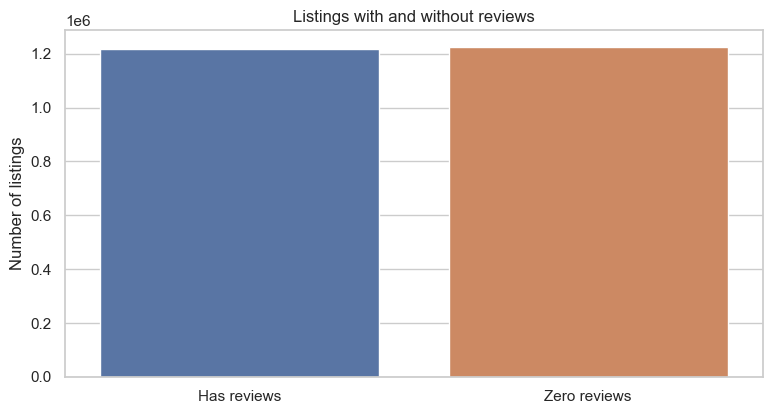

In [76]:
# Looking at the zero themselves
zero_reviews = prices["reviews"].eq(0).value_counts()

sns.barplot(
    x=zero_reviews.index,
    y=zero_reviews.values
)

plt.xticks([0, 1], ["Has reviews", "Zero reviews"])
plt.ylabel("Number of listings")
plt.title("Listings with and without reviews")
plt.show()

Based on this, I will be dropping the zero from the dataset. It skews the analysis too much, and I am more interested in the reviews of the products themselves.

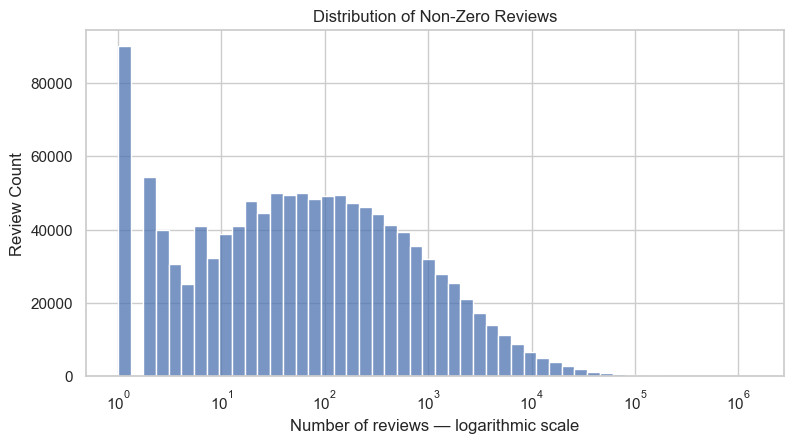

In [86]:
#filter out zeros
non_zero_reviews = prices.loc[prices["reviews"] > 0,"reviews"].dropna()

#Using log scale

ax = sns.histplot(non_zero_reviews, bins=50, log_scale=True, stat ="count")

ax.set_title("Distribution of Non-Zero Reviews")
ax.set_xlabel("Number of reviews — logarithmic scale")
ax.set_ylabel("Review Count")
plt.show()


This clearly shows that most of the reviews, discounting zeroes falls around 1-10 reviews, but 1 itself takes the most counts. Next thing to check is the skewness and kurtosis.

In [96]:
#Skewness & Kurtosis

pd.Series({"skew": rating['reviews'].skew(), "kurtosis": rating['reviews'].kurt()})


skew          102.817822
kurtosis    17741.014605
dtype: float64

The skew is towards the left (Although logarithmically, it looks centre), and this makes sense with my earlier observations. The kurtosis also shows why the higher reviews have a low count. It means that the curve is platykurtic, ergo, thin tailed.